# Aula 02 - Classificação, Regressão Logística, Redes Neurais e IA

In [ ]:
# Imports e Configuração Inicial
import random

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, mean_squared_error, r2_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


# Seeds de reprodutibilidade: garantem que os resultados sejam consistentes execuções para uma mesma seed
SEED = 314
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Classificação

Bom até agora aprendemos como uma regressão linear funciona, e como ela aprende, mas vamos espandir mais um pouco o escopo dos dados em que trabalhamos, dentro do mundo real há muitos momentos onde precisamos prever variaveis qualitativas, por exemplo, supondo que trabalhamos em um banco, e recebemos um conjunto de dados de informações das transações de vários clientes, nosso Y diz se a transação foi fraudulenta ou não, e esse valor vai ser dado por 0 se a transação foi normal e 1 se foi fraude.

A principal diferença desse caso para o que vimos até agora é justamente o que queremos prever, os valores a serem previstos são uma classe, ela classifica a transação como fraude ou não fraude, já anteriormente queriamos descobrir valores quantitativos e reais de -$\infty$ a +$\infty$.

Para esse caso de uso utilizamos os modelos de Classificação, existem inumeros modelos de classificação, tanto que fazem classificação binaria, onde a saída é duas classes diferentes, como se um e-mail é span ou não, se o paciente tem uma doença ou não, ou até para valores multclasse, como, por exemplo, dado caracteríscas de altura, peso, motor, e tamanho de um carro, qual categoria ele pertence.

# Regressão Logistica

Vamos pensar em um cenário específico onde temos dados da quantidade de transações que clientes de um banco fazem na semana, e o Y é se eles são fraudadores ou não;

Text(0.5, 0, 'Quantidade de transações')

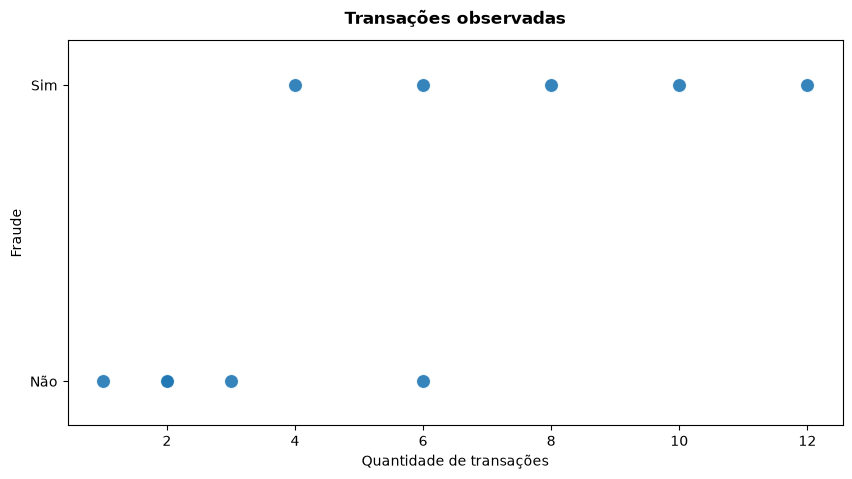

In [2]:
quant_transactions = np.array([2, 6, 1, 12, 2, 10, 3, 6, 4, 8]);
fraude = np.array([0, 0, 0, 1, 0, 1, 0, 1, 1, 1]);

fig, ax = plt.subplots(figsize=(10, 5))

sns.scatterplot(
    x=quant_transactions,
    y=fraude,
    s=110,
    color='#1f77b4',
    edgecolor='white',
    linewidth=1.2,
    alpha=0.9,
    ax=ax
)
ax.set_title('Transações observadas', pad=12, weight='bold')
ax.set_ylabel('Fraude')
ax.set_yticks([0, 1], labels=['Não', 'Sim'])
ax.set_ylim(-0.15, 1.15)
ax.set_xlabel('Quantidade de transações')

É claro que os dados não tem uma correlação linear, mas como sabemos apenas a regressão linear até agora, vamos utiliza-la para tentar aprender com esses dados;

In [3]:
x = quant_transactions.reshape(-1, 1)
model = LinearRegression();
model.fit(x, fraude)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.11]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.07353
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[11.06]


In [4]:
y_pred = model.predict(x)
mse = mean_squared_error(fraude, y_pred)
r2 = r2_score(fraude, y_pred)
print(f'Erro: {mse:.2f}')
print(f'Aprendizado: {r2:.2f}%')

Erro: 0.11
Aprendizado: 0.55%


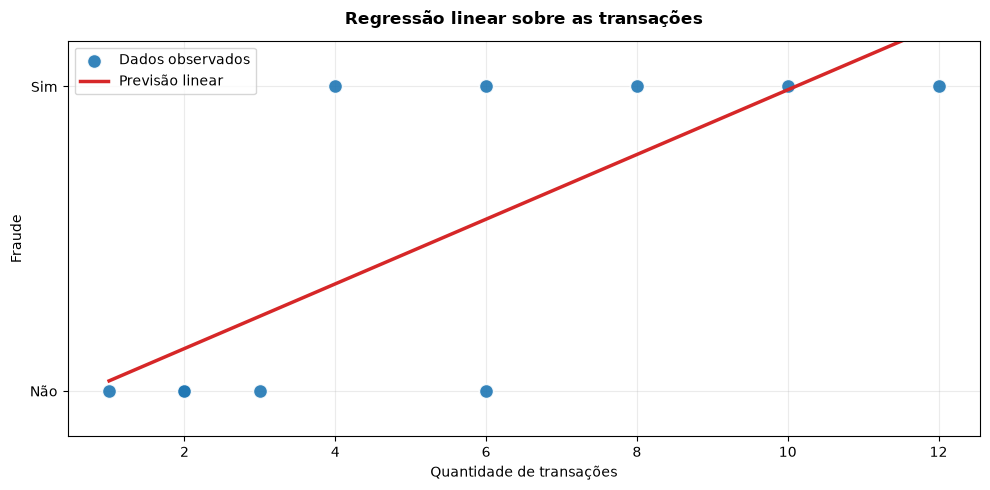

In [5]:
ordem = np.argsort(quant_transactions)
fig, ax = plt.subplots(figsize=(10, 5))

sns.scatterplot(
    x=quant_transactions,
    y=fraude,
    s=105,
    color='#1f77b4',
    edgecolor='white',
    linewidth=1.2,
    alpha=0.9,
    label='Dados observados',
    ax=ax
)
ax.plot(
    quant_transactions[ordem],
    y_pred[ordem],
    color='#d62728',
    linewidth=2.5,
    label='Previsão linear'
)
ax.set_title('Regressão linear sobre as transações', pad=12, weight='bold')
ax.set_yticks([0, 1], labels=['Não', 'Sim'])
ax.set_ylim(-0.15, 1.15)
ax.grid(alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=True)
ax.set_ylabel('Fraude')
ax.set_xlabel('Quantidade de transações')
ax.grid(axis='x', alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()

Podemos tirar algumas conclusões desses dados, primeiro que como já haviamos imaginado o modelo de regressão linear não é o mais apropriado para esse tipo de dado, mas por que?

Bom isso tem alguns motivos o primeiro já falamos, mesmo que o modelo seja treinado apenas com valores qualitativos de Y, ele não foi preparado para retornar apenas esse tipo de valores, então como visto no modelo, ele previu alguns valores maiores que 1, o que é impossível já que nosso Y só tem valores 0 ou 1, outro motivo é que nosso modelo fica muito sensível a outliers, vamos supor que esse mesmo modelo tenha um outlier, vamos ver como ele ficaria;

Erro: 0.19
Aprendizado: 0.23%


Text(0.5, 0, 'Quantidade de transações')

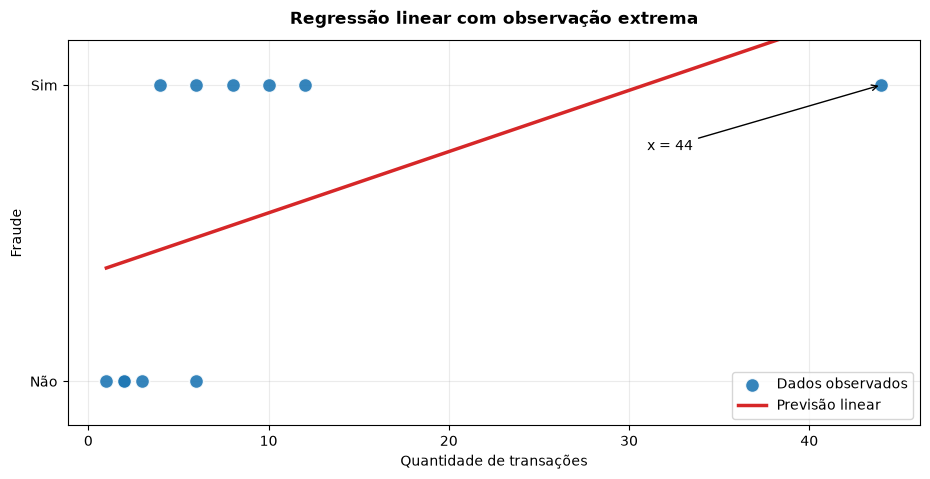

In [6]:
quant_transactions = np.array([2, 6, 1, 12, 2, 10, 3, 6, 4, 8, 44]);
fraude = np.array([0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1]);

x = quant_transactions.reshape(-1, 1)
model = LinearRegression();
model.fit(x, fraude)

y_pred = model.predict(x)
mse = mean_squared_error(fraude, y_pred)
r2 = r2_score(fraude, y_pred)
print(f'Erro: {mse:.2f}')
print(f'Aprendizado: {r2:.2f}%')

ordem = np.argsort(quant_transactions)
fig, ax = plt.subplots(figsize=(11, 5))

sns.scatterplot(
    x=quant_transactions,
    y=fraude,
    s=105,
    color='#1f77b4',
    edgecolor='white',
    linewidth=1.2,
    alpha=0.9,
    label='Dados observados',
    ax=ax
)
ax.plot(
    quant_transactions[ordem],
    y_pred[ordem],
    color='#d62728',
    linewidth=2.5,
    label='Previsão linear'
)
ax.set_title('Regressão linear com observação extrema', pad=12, weight='bold')
ax.set_yticks([0, 1], labels=['Não', 'Sim'])
ax.set_ylim(-0.15, 1.15)
ax.grid(alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=True)
ax.annotate('x = 44', xy=(44, 1), xytext=(31, 0.78), arrowprops={'arrowstyle': '->'})
ax.set_ylabel('Fraude')
ax.set_xlabel('Quantidade de transações')

Ok, já entendemos que não podemos usar somente a regressão linear nesse caso, mas qual curva descreve melhor esses dados?

A regressão logística estima a **probabilidade** de uma observação pertencer à classe 1. Para isso, ela usa uma curva sigmoide, em formato de S, cujos valores sempre ficam entre 0 e 1.

Para visualizar essa curva, não podemos usar `model.predict()`: esse método já transforma a probabilidade em uma classe final, 0 ou 1, usando por padrão o limiar de 0,5. Por isso, ele gera apenas pontos ou degraus. Usamos `model.predict_proba()` para obter a probabilidade de fraude e calculamos essa probabilidade para uma sequência ordenada de quantidades de transações.

O valor 44 é um possível outlier e amplia muito o eixo x. Assim, a parte curva da sigmoide, que ocorre aproximadamente entre 0 e 12 transações, parece comprimida no gráfico completo. Os dois gráficos abaixo mostram a mesma curva: o primeiro preserva a escala completa e o segundo amplia a região em que a transição acontece.

Acurácia no treino: 80.00%


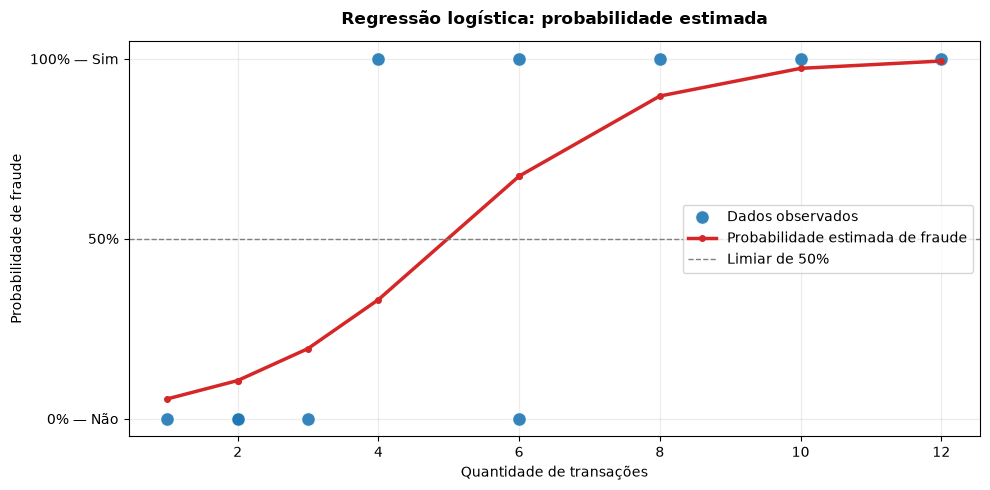

In [7]:
quant_transactions = np.array([2, 6, 1, 12, 2, 10, 3, 6, 4, 8]);
fraude = np.array([0, 0, 0, 1, 0, 1, 0, 1, 1, 1]);

x = quant_transactions.reshape(-1, 1)
model = LogisticRegression();
model.fit(x, fraude)

print(f'Acurácia no treino: {model.score(x, fraude) * 100:.2f}%')

prob_fraude = model.predict_proba(x)


ordem = np.argsort(quant_transactions)
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(
    x=quant_transactions,
    y=fraude,
    s=105,
    color='#1f77b4',
    edgecolor='white',
    linewidth=1.2,
    alpha=0.9,
    label='Dados observados',
    ax=ax
)
ax.plot(
    quant_transactions[ordem],
    prob_fraude[ordem, 1],
    color='#d62728',
    linewidth=2.5,
    marker='o',
    markersize=4,
    label='Probabilidade estimada de fraude'
)
ax.axhline(0.5, color='gray', linestyle='--', linewidth=1, label='Limiar de 50%')
ax.set_title('Regressão logística: probabilidade estimada', pad=12, weight='bold')
ax.set_xlabel('Quantidade de transações')
ax.set_ylabel('Probabilidade de fraude')
ax.set_yticks([0, 0.5, 1], labels=['0% — Não', '50%', '100% — Sim'])
ax.set_ylim(-0.05, 1.05)
ax.grid(alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=True, loc='center right')
plt.tight_layout()

Acurácia no treino: 81.82%


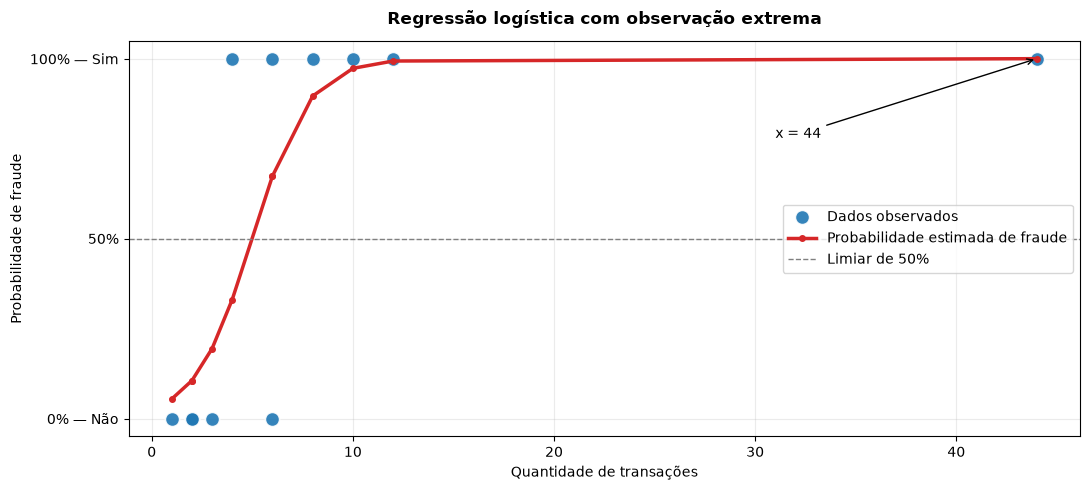

In [8]:
quant_transactions = np.array([2, 6, 1, 12, 2, 10, 3, 6, 4, 8, 44]);
fraude = np.array([0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1]);

x = quant_transactions.reshape(-1, 1)
model = LogisticRegression();
model.fit(x, fraude)

print(f'Acurácia no treino: {model.score(x, fraude) * 100:.2f}%')

prob_fraude = model.predict_proba(x)


ordem = np.argsort(quant_transactions)
fig, ax = plt.subplots(figsize=(11, 5))
sns.scatterplot(
    x=quant_transactions,
    y=fraude,
    s=105,
    color='#1f77b4',
    edgecolor='white',
    linewidth=1.2,
    alpha=0.9,
    label='Dados observados',
    ax=ax
)
ax.plot(
    quant_transactions[ordem],
    prob_fraude[ordem, 1],
    color='#d62728',
    linewidth=2.5,
    marker='o',
    markersize=4,
    label='Probabilidade estimada de fraude'
)
ax.axhline(0.5, color='gray', linestyle='--', linewidth=1, label='Limiar de 50%')
ax.set_title('Regressão logística com observação extrema', pad=12, weight='bold')
ax.set_xlabel('Quantidade de transações')
ax.set_ylabel('Probabilidade de fraude')
ax.set_yticks([0, 0.5, 1], labels=['0% — Não', '50%', '100% — Sim'])
ax.set_ylim(-0.05, 1.05)
ax.grid(alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=True, loc='center right')
ax.annotate('x = 44', xy=(44, 1), xytext=(31, 0.78), arrowprops={'arrowstyle': '->'})
plt.tight_layout()

É notável que ela além de ter um desempenho muito melhor com os dados, a regressão logistica é muito menos sensível a outliers, mas como ela funciona?

A regressão logística é uma regressão com uma função de ativação sigmoid que nos retorna um valor entre 0 e 1 que é a probabilidade do $\hat Y$ ser 1;

$$P(Y = 1 \mid x) = \frac{1}{1 + e^{-z}} ou \frac{e^z}{1 + e^z}$$
É notável que, além de apresentar um bom desempenho nesses dados, a regressão logística seja menos sensível a valores extremos. 
A regressão logística calcula uma combinação linear das entradas, $z = WX + b$, e aplica a função sigmoide. O resultado é um valor entre 0 e 1, interpretado como a probabilidade de $\hat{Y}$ pertencer à classe 1:

$$
P(Y = 1 \mid X) = \sigma(z) = \frac{1}{1 + e^{-z}} = \frac{e^z}{1 + e^z}
$$

onde $z = WX + b$, $\sigma$ representa a função sigmoide e $e$ é a constante de Euler, aproximadamente igual a 2,718.
$$p = \sigma(WX+b)$$

onde $z$ é nossa função linear $WX + b$ e $e$ é a constante de Euler aproximadamente 2,718;



Vamos fazer um exemplo prático onde $W = 0.5$ $b = -3$ $ X = 2$
Substituindo os valores, primeiro calculamos:

$$z = wX + b = 0.5 \cdot 2 - 3 = -2$$

Então, a probabilidade de $Y = 1$ é:

$$P(Y = 1 \mid x) = \frac{1}{1 + e^{-z}} = \frac{1}{1 + e^2} $$

In [9]:
#Prática da função

a = 0.5
x = 2
b = -3

def FuncaoLogistica(a, x, b):
    e = 2.718
    z = a *x +b
    resultado = 1 / (1 + e ** (-z))
    return resultado

logistic = FuncaoLogistica(a, x, b)
print(f'{logistic:.2}')


0.12


Agora entendemos como nosso modelo calcula as probabilidades, mas como nosso modelo aprende?

Dentro da Regressão linear nossa função de custo era a Mean Squared Error, mas ela não vai funcionar muito bem com nossa regressão logistica, para esse modelo vamos usar a Binary Cross Entropy

# Função de Custo Binary Cross Entropy

Vamos entender melhor essa função de custom por que binaria? o que é entropia cruzada?

**Teoria da informação** <br>

O termo entropia vem da teoria da informação, mais especificamente do paper "A Mathematical Theory of Comunnication" que foi publicada por Claude Shannon em 1948 (Inspiração do Dario Amoday para o nome do Claude Code), dentro desse artigo a preocupação dele era sobre como transmitir mensagens ou informações por meio de um canal, ele queria entender qual seria a melhor forma e a forma mais eficiente possível dessa transmissão acontecer.

Dentro desse paper surgiu o conceito de entropia cruzada, mas antes de entendermos o que é a cross entropy, precisamos voltar um pouco, vamos entender o que era informação para o Claude.

**Informação**

A informação vai quantificar a incerteza de um evento, ou seja, quanto maior informação que precisamos menor é a probabilidade de um evento acontecer, e eventos de alta probabilidade são menos surpreendentes, então precisam de menos informação para acontecer;
fórmula da informação <br>
$I(x) = -LogP(x)$
Exemplo:

Supondo que queremos descobrir a quantidade de informação que precisamos para que um time seja campeão mundial as probabilidades são
Corinthians(60%) <br>
Real Madrid(20%) <br>
Al Hilal(20%) <br>
Palmeiras(0%) <br>

A informação que precisamos para o Corinthians ser campeão, é $-ln(0,60)$ que é aproximadamente $0,51$; <br>
A informação que precisamos para o Real Madrid ser campeão, é $-ln(0,20)$ que é aproximadamente $1,60$; <br>
A informação que precisamos para o Al Hilal ser campeão, é $-ln(0,20)$ que é aproximadamente $1,60$; <br>

Com esses dados é possível vizualizar e consolidar o que foi teorizado por Sannon, que quanto menor a probabilidade maior a quantidade de informação que precisamos para que esse evento aconteça;

**Entropia**

A entropia quantifica a quantidade de informação relativa de uma variável dado uma distribuição de probabilidades, ou seja, diferente da informação que quantifica infromações apenas para um evento, a entropia calcula a quantidade de informação para uma varivel;

Vamos ver um exemplo dessa diferença, dentro do exemplo acima descrimos a quantidade de informação que precisamos para o evento Corinthians compeão mundial, Real madrid campeão mundial ou Al hilal campeão mundial, já a entropia calcularia a quantidade de informação da variavel "quem será campeão mundial?" dado o conjunto de probabilidades de cada clube;

$$
H(X) = -\sum_{i=1}^{n} p(x_i)\log p(x_i)
$$

onde $p(x_i)$ é a probabilidade de cada resultado possível, ou seja, somamos o produto da probabilidade de cada evento pela quantidade de informação que ele precisa.

Ficaria então = $$- (0,6\log(0,6)) + (0,2\log(0,2)) + (0,2\log(0,2)) \approx 0,95 $$ de informação em média


In [10]:
#construir uma função que calcula a informação
def Informacao(p):
    return -np.log(p)
print(f'{Informacao(0.2):.2f}')

1.61


In [11]:
#construir uma função que calcula entropia
def Entropia(p):
    entropia = 0
    for i in p:
        entropia -= i * np.log(i)
    return entropia
p = [0.6, 0.2, 0.2]

print(Entropia(p))

0.9502705392332347



**Entropia Cruzada**

Agora falar de Cross entropy é muito mais fácil, já que a entropia cruzada é a entropia relativa de duas distribuições de probabilidade, para exemplificar, vamos supor que nosso evento de times sejá a probabilidade que uma casa de aposta publicou com base em um estudo que ela fez, já outra casa de aposta fez outro estudo onde as probabilidades eram:

        Casa A                    |                  Casa B        
    Corinthians (60%)             |              Corinthians (90%) 
    Real madrid (20%)             |              Real madrid (8%)  
    Al Hilal (20%)                |              Al Hilal (2%)     

Para calcular a entropia cruzada dessas duas distribuições de probabilidade vamo utilizar a formula:

A entropia cruzada entre uma distribuição de referência $P$ e uma distribuição estimada $Q$ é:

$$
H(P,Q) = -\sum_{i=1}^{n} p(x_i)\log q(x_i)
$$

Considerando a Casa A como distribuição de referência e a Casa B como estimativa:

$$
H(P,Q) = -\bigl[
0{,}6\ln(0{,}9) +
0{,}2\ln(0{,}08) +
0{,}2\ln(0{,}02)
\bigr]
\approx 1{,}35
$$

E se calculassemos a entropia deles individualmente, teríamos:

$$
H(P) = -\sum_{i} p_i \ln(p_i)
= -\bigl[0{,}6\ln(0{,}6) + 0{,}2\ln(0{,}2) + 0{,}2\ln(0{,}2)\bigr]
\approx 0{,}95
$$

e

$$
H(Q) = -\sum_{i} q_i \ln(q_i)
= -\bigl[0{,}9\ln(0{,}9) + 0{,}08\ln(0{,}08) + 0{,}02\ln(0{,}02)\bigr]
\approx 0{,}38
$$

Ou seja, a distribuição da Casa A tem uma entropia maior, porque como as probabilidades dos times são mais próxima isso torna o evento mais incerto, o que significa que precisariamos que mais informação para saber se ele aconteceria. Isso também explica por que a entropia cruzada $H(P,Q)$ é maior que a entropia de $P$ e de $Q$ individualmente: ela mede o custo de aproximar duas distribuições diferentes.


**Binary Cross Entropy**

A entropia binária cruzada (*binary cross-entropy*, ou BCE) adapta essa ideia a problemas de classificação binária. Para $N$ amostras, ela é definida como:

$$
\mathrm{BCE}
= -\frac{1}{N}\sum_{i=1}^{N}
\left[
y_i\ln(\hat{y}_i) +
(1-y_i)\ln(1-\hat{y}_i)
\right]
$$

- $N$: número de amostras.
- $y_i$: rótulo real da amostra $i$, igual a $0$ ou $1$.
- $\hat{y}_i$: probabilidade prevista pelo modelo de que a amostra pertença à classe $1$, entre $0$ e $1$ — calculada com a função sigmoide.

Essa função de custo é muito interessante pois ela é quase duas funções em uma, pois quando o valor for negativo vamos usar o lado direito da função, e quando for positivo vamos usar o lado esquerdo, mas vamos entender como isso funciona:

supondo que utilizamos o resultado da função sigmoid que calculamos lá em cima;

Caso $y_i$ = 1:
$$- 1\ln(0.1192) + (1-1) \ln(1-0,1192)$$
$$- 1\ln(0.1192)$$
$$-(-2,12)$$
Resultado = $\approx2,12$


Note que nesse caso o lado direito vai sair da fórmula pois vamos multiplica-lo por 0 após subtrairmos $1 - (\hat{y_i})$ já que nosso $(\hat{y_i})$ é 1;

Caso $y_i$ = 0:

$$- 0\ln(0.1192) + (1-0) \ln(1-0,1192)$$
$$- 1\ln(0,88)$$
$$-(-0,12)$$

Resultado = $\approx0,12$

Nesse caso cortamos a parte esqueda da equação, já que nosso $y_i$ = 0, também é possível notar que nossa função de custo retornou um valor bem maior quando o valor original era 1, já que nosso modelo errou bem mais de que quando era 0, dado que o $\hat{y}$ era 11,92% de chance do valor ser 1.

Para minimizar essa função vamos utilizar o conceito de gradiente descente aprendidos na última aula.

**Decision Boundary**

Também precisamos definir a fronteira de decisão. Por padrão, usamos o limiar de 50%: se a probabilidade estimada de a observação pertencer à classe 1 for maior ou igual a 50%, classificamos o resultado como 1; caso contrário, classificamos como 0.

Como a função sigmoide é crescente e $\sigma(0)=0{,}5$, esse critério também pode ser escrito em função de $z$:

$$
\hat{y} \geq 0{,}5 \iff z \geq 0
$$

$$
\hat{y} < 0{,}5 \iff z < 0
$$ 

Há também casos onde precisaremos mudar a decision boundary, pois queremos um modelo com uma precisão muito grando, para casos onde estamos lidando com classificação de remédios por exemplo.


# Aplicando Regressão Logistica em um dataset Real

In [12]:
df = pd.read_csv('datasets/Diagnosis.csv')
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

In [14]:
df = df.drop(columns=['id', 'Unnamed: 32'])
df = df.dropna()
df['diagnosis'] = df['diagnosis'].replace({'M': 0, 'B': 1}).astype(float)
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,0.0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,0.0,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,0.0,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,0.0,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,0.0,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


<Axes: xlabel='radius_mean', ylabel='diagnosis'>

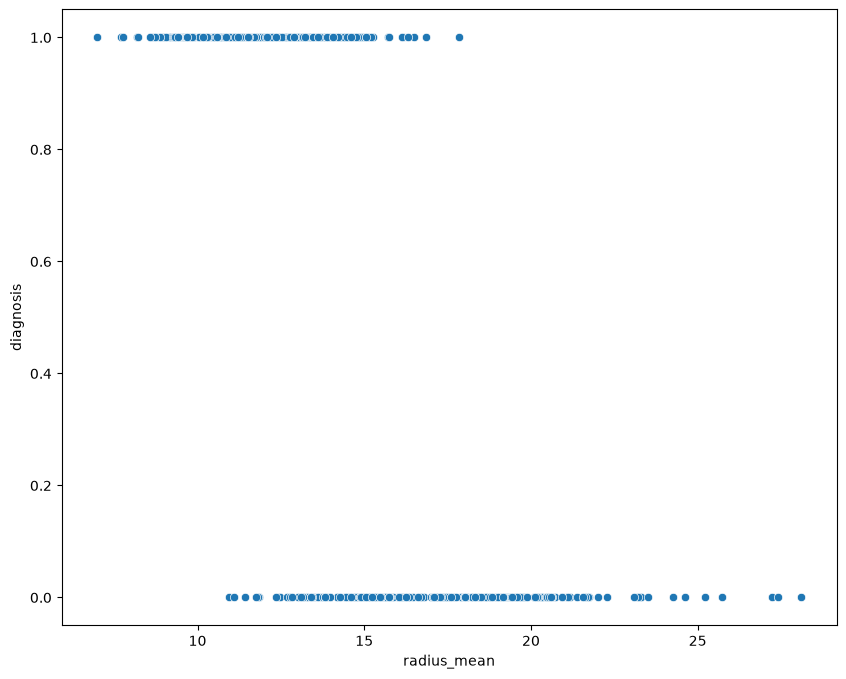

In [15]:
#scatter plot Radius_mean e Diagnosis
fig, ax = plt.subplots(figsize=(10,8))
sns.scatterplot(x=df['radius_mean'], y=df['diagnosis'])

In [16]:
#Construndo o modelo com sklearn
x = df.drop(columns='diagnosis')
y = df['diagnosis']
modelo = LogisticRegression()
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

LogisticRegressor = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)
LogisticRegressor.fit(x_train, y_train)
print(f'Acurácia no treino: {LogisticRegressor.score(x_train, y_train) * 100:.2f}%')
print(f'Acurácia no teste: {LogisticRegressor.score(x_test, y_test) * 100:.2f}%')

Acurácia no treino: 98.68%
Acurácia no teste: 97.37%


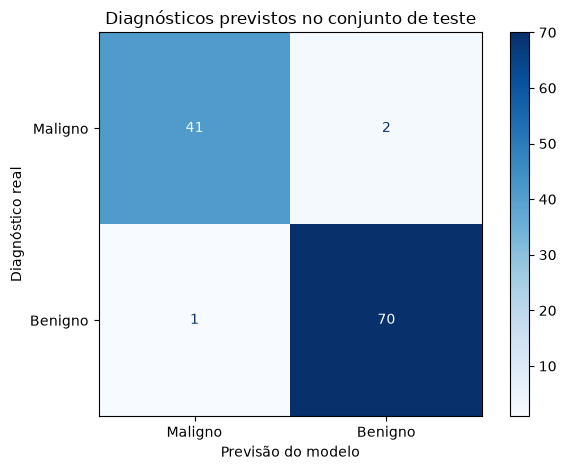

In [17]:
y_pred = LogisticRegressor.predict(x_test)

matriz = confusion_matrix(y_test, y_pred, labels=[0, 1])

grafico = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=['Maligno', 'Benigno']
)
grafico.plot(cmap='Blues', values_format='d')

plt.title('Diagnósticos previstos no conjunto de teste')
plt.xlabel('Previsão do modelo')
plt.ylabel('Diagnóstico real')
plt.tight_layout()
plt.show()

# Aula 02 Parte 02 - Redes Neurais, Embeddings e IA

---
## Do neurônio à rede neural

### O que é um neurônio artificial?

Uma rede neural artificial é um modelo computacional inspirado, de forma simplificada, pelo funcionamento de redes de neurônios biológicos. Cada neurônio recebe números, combina esses números por meio de parâmetros aprendidos e produz uma saída. Durante o treinamento, os parâmetros são ajustados para que as previsões se tornem mais adequadas aos exemplos apresentados, corrigindo com base em uma função de custo.

Se isso soa familiar, é por que é mesmo: numa rede neural, é como se cada neurônio fosse uma "mini" regressão-linear, porém, com uma função de ativação no final, que logo expericaremos.

Um neurônio artificial costuma realizar duas operações:

1. combinar as entradas usando **pesos** e um **viés** (*bias*);
2. aplicar uma **função de ativação** ao resultado final.

Para entradas $x_1, x_2, \ldots, x_n$, pesos $w_1, w_2, \ldots, w_n$ e viés $b$, a combinação é:

$$
z = \sum_{i=1}^{n} w_i x_i + b
$$

A ativação produz a saída:

$$
a = f(z)
$$

*Ou seja, os pesos dizem quanto cada entrada contribui para a combinação; o viés desloca o resultado; a ativação transforma a combinação antes de enviá-la adiante. Vejamos um exemplo de um neurônio simples, usando a função de ativação *ReLU*:

In [18]:
# Um neurônio artificial com duas entradas
entradas = torch.tensor([2.0, 3.0])
pesos = torch.tensor([0.5, -0.25])
vies = torch.tensor(0.1)

z = torch.dot(pesos, entradas) + vies

saida_relu = torch.relu(z)

saida_sigmoide = torch.sigmoid(z)

print(f"Entradas: {entradas.tolist()}")
print(f"Combinação ponderada z: {z.item():.3f}")
print(f"Saída com ReLU: {saida_relu.item():.3f}")
print(f"Saída com sigmoide: {saida_sigmoide.item():.3f}")

Entradas: [2.0, 3.0]
Combinação ponderada z: 0.350
Saída com ReLU: 0.350
Saída com sigmoide: 0.587


Neste exemplo, $z = 0{,}5(2) - 0{,}25(3) + 0{,}1 = 0{,}35$. A ReLU mantém esse valor porque ele é positivo. A sigmoide transforma o mesmo valor em um número entre 0 e 1. O neurônio ainda não está aprendendo aqui: os pesos e o viés foram escolhidos manualmente para mostrar a conta.

### E o perceptron?

O perceptron, proposto por Frank Rosenblatt no final da década de 1950, foi um dos primeiros modelos de neurônio artificial. Em sua concepção original, o perceptron se assemelhava muito ao modelo de Regressão Logística, com a diferença de que usamos uma função de ativação diferente, chamada de degrau, enquanto a logística utiliza a sigmoide. Existem mais de um tipo de função degrau, mas a mais conhecida é a heaviside:

$$
a = \begin{cases} 1, & z \geq 0 \\ 0, & z < 0 \end{cases}
$$

Note que, usar um único perceptron e utilizar uma função de ativação como a sigmoide como função de ativação, fará o perceptron agir exatamente como uma regressão logística.

## 2. Por que usar funções de ativação?
A Álgebra Linear nos fornece as ferramentas necessárias para entedermos mais profundamente essa questão, mas, de maneira intuitiva: empilhar *transformações lineares* faz com que o *todo* também seja, necessariamentem linear. Isto é: utilizar vários neurônios, todos lineares, equivale a utilizar apenas UM grande neurônio linear, e muitos fenômenos mais complexos (como por exemplo, imagens) que podemos querer treinar nossos modelos são *não-lineares*. Assim, uma função de ativação introduz *não linearidade* nos dados.

Existem vários tipos de funções de ativação, dentre as quais as mais comuns são:

As **funções de ativação não lineares** tornam possível aprender relações mais ricas. Duas funções bastante comuns são:

- **ReLU:** $\operatorname{ReLU}(z)=\max(0,z)$. Valores negativos viram zero; valores positivos são preservados.
- **Sigmoide:** $\sigma(z)=\frac{1}{1+e^{-z}}$. Transforma qualquer número real em um valor entre 0 e 1.

A ReLU é muito usada nas camadas escondidas do modelo (logo veremos). Já a sigmoide costuma ser usada na camada de saída, para interpretar a saída de um classificador binário que devolve um *logito*.

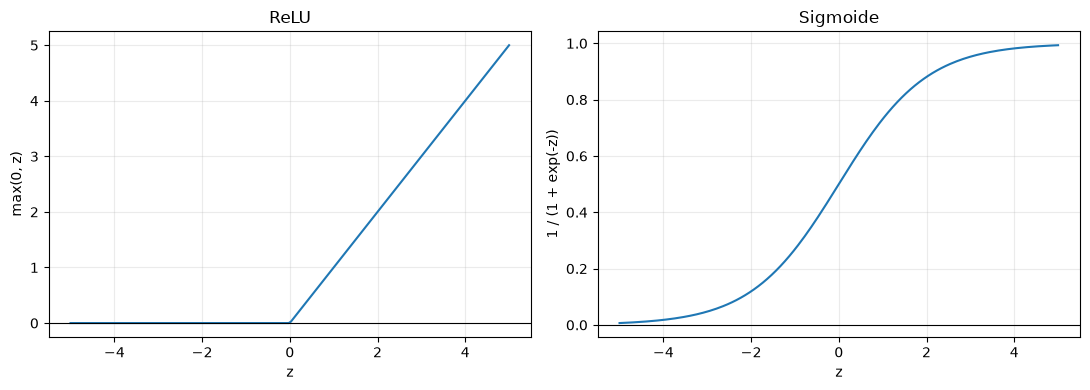

In [19]:
valores = torch.linspace(-5, 5, 200)
relu = torch.relu(valores)
sigmoide = torch.sigmoid(valores)

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
eixos[0].plot(valores.numpy(), relu.numpy())
eixos[0].set_title("ReLU")
eixos[0].set_xlabel("z")
eixos[0].set_ylabel("max(0, z)")
eixos[1].plot(valores.numpy(), sigmoide.numpy())
eixos[1].set_title("Sigmoide")
eixos[1].set_xlabel("z")
eixos[1].set_ylabel("1 / (1 + exp(-z))")
for eixo in eixos:
    eixo.axhline(0, color="black", linewidth=0.8)
    eixo.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**O que observar:** a ReLU é zero para entradas negativas e cresce linearmente para entradas positivas. A sigmoide é suave e fica entre 0 e 1. As duas têm funções diferentes; não são peças intercambiáveis em qualquer lugar da rede.

## 3. Entradas, camadas escondidas e saída

Uma **característica** (*feature*) é uma informação usada pelo modelo para fazer uma previsão. Para estimar se um estudante será aprovado, por exemplo, poderíamos usar horas de estudo e quantidade de exercícios resolvidos. Uma observação seria representada por um vetor:

$$
x = [x_1, x_2]
$$

Uma rede neural pode ter:

- **Camada de entrada:** recebe as características numéricas do exemplo. Não é necessariamente uma camada de neurônios com parâmetros próprios; frequentemente é apenas a forma de representar os dados de entrada.
- **Camada(s) escondida(s):** combina(m) as entradas usando pesos, vieses e ativações. Neurônios diferentes podem aprender combinações diferentes.
- **Camada de saída:** produz o valor apropriado para a tarefa, como um valor contínuo numa regressão ou um escore para classificação.

O diagrama conceitual é:

$$
\text{entradas} \rightarrow \text{camada escondida} \rightarrow \text{saída}
$$

O tamanho de cada camada depende da arquitetura. Uma camada escondida com quatro neurônios produz quatro valores intermediários para cada exemplo.

### Como ler `nn.Linear(2, 4)`?

Em PyTorch, `nn.Linear(in_features, out_features)` implementa uma transformação afim: combina as entradas com pesos e soma um viés. Assim:

- `nn.Linear(2, 4)` recebe 2 características e produz 4 valores;
- `nn.Linear(4, 1)` recebe esses 4 valores e produz 1 saída.

Para um lote com $m$ exemplos, as dimensões são:

| Objeto | Formato | Interpretação |
|---|---|---|
| Entrada $X$ | $(m,2)$ | $m$ exemplos, 2 características |
| Pesos da primeira camada $W_1$ | $(4,2)$ | 4 neurônios, cada um com 2 pesos |
| Viés da primeira camada $b_1$ | $(4,)$ | 1 viés por neurônio escondido |
| Saída escondida $H$ | $(m,4)$ | 4 ativações por exemplo |
| Pesos da saída $W_2$ | $(1,4)$ | 1 neurônio de saída ligado a 4 ativações |
| Viés da saída $b_2$ | $(1,)$ | 1 viés para o neurônio de saída |

Os índices em $W_1,b_1,W_2,b_2$ identificam **a camada**. O número 2 em $W_2$ e $b_2$, por exemplo, não significa elevar nada ao quadrado: significa que os parâmetros pertencem à segunda camada com parâmetros.

In [20]:
torch.manual_seed(SEED)
rede_exemplo = nn.Sequential(
    nn.Linear(2, 4),
    nn.ReLU(),
    nn.Linear(4, 1),
)

entrada_exemplo = torch.tensor([[0.6, 0.4]])  # features normalizadas: um exemplo, duas entradas
logit_exemplo = rede_exemplo(entrada_exemplo)
probabilidade_exemplo = torch.sigmoid(logit_exemplo)

print(rede_exemplo)
print("Formato da entrada:", tuple(entrada_exemplo.shape))
print("Pesos da primeira camada:", tuple(rede_exemplo[0].weight.shape))
print("Viés da primeira camada:", tuple(rede_exemplo[0].bias.shape))
print("Pesos da camada de saída:", tuple(rede_exemplo[2].weight.shape))
print("Viés da camada de saída:", tuple(rede_exemplo[2].bias.shape))
print(f"Logit inicial: {logit_exemplo.item():.3f}")
print(f"Probabilidade inicial: {probabilidade_exemplo.item():.3f}")

Sequential(
  (0): Linear(in_features=2, out_features=4, bias=True)
  (1): ReLU()
  (2): Linear(in_features=4, out_features=1, bias=True)
)
Formato da entrada: (1, 2)
Pesos da primeira camada: (4, 2)
Viés da primeira camada: (4,)
Pesos da camada de saída: (1, 4)
Viés da camada de saída: (1,)
Logit inicial: 0.015
Probabilidade inicial: 0.504


**Por que a previsão é chamada de inicial?** Quando criamos a rede, o PyTorch inicializa seus parâmetros automaticamente. Em geral, os valores são inicializados por um procedimento apropriado, não simplesmente zerados. Antes do treinamento, a rede ainda não ajustou esses parâmetros para resolver a tarefa e sua saída normalmente não é útil.

### Passada para frente (*forward pass* ou *feedforward*)

A **passada para frente** é o cálculo que leva a entrada até a saída. Nesta rede, podemos escrever:

$$
Z_1 = XW_1^\top + b_1,\qquad H=\operatorname{ReLU}(Z_1)
$$
$$
Z_2 = HW_2^\top + b_2
$$

Aqui, $Z_2$ é o logit da saída. Para classificação binária, a sigmoide transforma esse logit numa probabilidade estimada. A notação com matrizes pode parecer abstrata, mas representa a mesma operação de combinar números que fizemos no exemplo de um único neurônio, repetida em vários neurônios e exemplos.

In [21]:
# Passada para frente manual, com parâmetros fixados para tornar as dimensões explícitas
X = torch.tensor([[0.6, 0.4]])  # duas features já normalizadas
W1 = torch.tensor([
    [0.8,  0.1],
    [0.2,  0.7],
    [-0.5, 0.3],
    [0.4, -0.2],
])  # formato (4, 2)
b1 = torch.tensor([0.1, -0.4, 0.2, 0.0])      # formato (4,)
W2 = torch.tensor([[0.6, -0.3, 0.4, 0.5]])    # formato (1, 4)
b2 = torch.tensor([0.2])                     # formato (1,)

Z1 = X @ W1.T + b1
H = torch.relu(Z1)
Z2 = H @ W2.T + b2
P = torch.sigmoid(Z2)

print("X:", X.shape)
print("W1:", W1.shape, "| b1:", b1.shape)
print("Z1:", Z1, "| H depois da ReLU:", H)
print("W2:", W2.shape, "| b2:", b2.shape)
print(f"Logit final: {Z2.item():.3f}")
print(f"Probabilidade ilustrativa: {P.item():.3f}")

X: torch.Size([1, 2])
W1: torch.Size([4, 2]) | b1: torch.Size([4])
Z1: tensor([[0.6200, 0.0000, 0.0200, 0.1600]]) | H depois da ReLU: tensor([[0.6200, 0.0000, 0.0200, 0.1600]])
W2: torch.Size([1, 4]) | b2: torch.Size([1])
Logit final: 0.660
Probabilidade ilustrativa: 0.659


Esta implementação manual serve para enxergar a álgebra. No uso normal, `nn.Linear` guarda os pesos e vieses e executa essas operações por nós. O operador `@` representa multiplicação matricial; a transposição em `W1.T` ajusta as dimensões para que a multiplicação seja possível.

### Logit não é probabilidade

Um **logit** é um escore real, sem restrição a um intervalo específico. A sigmoide transforma o logit em um valor entre 0 e 1. Em muitos problemas binários, interpretamos esse valor como a probabilidade estimada de pertencer à classe positiva. A decisão final pode ser feita usando um limiar, como 0,5, embora esse limiar dependa do contexto e do custo dos erros.

---
# Parte 2 — Como uma rede aprende

## 4. A função de perda: transformar o erro em um número

Uma previsão, sozinha, não diz se o modelo está acertando. Precisamos compará-la com o resultado esperado. A **função de perda** (*loss function*) transforma essa comparação em um número que o treinamento tentará reduzir.

Para classificação binária, usamos com frequência a entropia cruzada binária (*Binary Cross-Entropy*, BCE). Para um rótulo $y\in\{0,1\}$ e uma probabilidade prevista $p$:

$$
\ell(y,p)=-\big[y\log(p)+(1-y)\log(1-p)\big]
$$

Quando o rótulo verdadeiro é 1, prever uma probabilidade próxima de 1 gera perda pequena e prever uma probabilidade próxima de 0 gera perda grande. O raciocínio é invertido quando o rótulo é 0. A perda penaliza previsões confiantes e erradas.

Na prática, o PyTorch oferece `nn.BCEWithLogitsLoss`, que combina a operação de sigmoide e a BCE de forma numericamente estável. Por isso, passamos os **logits** para essa função, sem aplicar manualmente a sigmoide antes dela.

In [22]:
logits_teste = torch.tensor([2.0, -1.0, 0.2], requires_grad=True)
rótulos_teste = torch.tensor([1.0, 0.0, 1.0])

funcao_perda = nn.BCEWithLogitsLoss()
perda_teste = funcao_perda(logits_teste, rótulos_teste)

print(f"Perda média do lote: {perda_teste.item():.4f}")

Perda média do lote: 0.3461


## 5. Gradientes e backpropagation

Para reduzir a perda, o modelo precisa descobrir como pequenas mudanças nos seus parâmetros afetam o resultado. Um **gradiente** informa a direção em que uma função aumenta mais rapidamente em relação aos parâmetros. Para reduzir a perda, o otimizador costuma atualizar os parâmetros na direção oposta ao gradiente.

O **backpropagation** (*retropropagação*) é o procedimento que calcula gradientes para os parâmetros da rede, aplicando a regra da cadeia ao longo das operações realizadas na passada para frente. O PyTorch consegue calcular esses gradientes automaticamente por meio do seu mecanismo de diferenciação automática (*autograd*).

O fluxo de treinamento pode ser resumido assim:

1. calcular as previsões (*forward pass*);
2. calcular a perda comparando previsões e rótulos;
3. zerar os gradientes acumulados de passos anteriores;
4. chamar `loss.backward()` para calcular os gradientes;
5. chamar `optimizer.step()` para atualizar os parâmetros;
6. repetir em outros lotes e épocas.

Uma **época** é uma passagem pelo conjunto de treinamento. Um *lote* (*batch*) é um subconjunto de exemplos usado em uma atualização dos parâmetros.

In [23]:
# O autograd calcula derivadas para nós
logits = torch.tensor([2.0, -1.0, 0.2], requires_grad=True)
rótulos = torch.tensor([1.0, 0.0, 1.0])
loss = nn.BCEWithLogitsLoss()(logits, rótulos)
loss.backward()

print(f"Perda: {loss.item():.4f}")
print("Gradientes dos logits:", logits.grad)

Perda: 0.3461
Gradientes dos logits: tensor([-0.0397,  0.0896, -0.1501])


O exemplo acima calcula gradientes em relação aos logits, não treina uma rede inteira. A ideia é observar que `backward()` preenche o atributo `.grad` para os tensores que participam do cálculo e foram configurados para acompanhar gradientes.

### Um único passo de atualização

O gradiente descendente atualiza um parâmetro $\theta$ conforme:

$$
\theta \leftarrow \theta - \eta\,\nabla_{\theta}J
$$

$\theta$ representa um parâmetro, $J$ é a função de perda e $\eta$ é a taxa de aprendizado (*learning rate*). Se a taxa for muito alta, o treinamento pode oscilar ou divergir; se for muito baixa, pode levar muito tempo para aprender. Otimizadores como Adam adaptam a forma como as atualizações são realizadas, mas a intuição básica permanece: usar gradientes para ajustar os parâmetros.

In [24]:
parametro = torch.tensor(2.5, requires_grad=True)
custo = parametro ** 2
custo.backward()  # derivada de theta^2: 2*theta = 5

with torch.no_grad():
    parametro -= 0.2 * parametro.grad

print("Gradiente calculado:", 5.0)
print(f"Parâmetro após um passo: {parametro.item():.2f}")

Gradiente calculado: 5.0
Parâmetro após um passo: 1.50


## 6. Treinando uma rede neural pequena

Vamos usar um conjunto **sintético** inspirado no exemplo de aprovação de estudantes. Cada observação terá duas características: horas de estudo e exercícios resolvidos. Os rótulos 0 e 1 são gerados por uma regra conhecida, com um pouco de ruído, apenas para construirmos um exemplo controlado.

**Importante:** esses dados foram inventados para ensinar o mecanismo. O resultado não é um estudo sobre estudantes reais e não deve ser usado para tomar decisões reais sobre aprovação.

Dividiremos os dados em treino e teste. A rede ajustará seus parâmetros apenas usando o conjunto de treino; ao final, avaliaremos seu desempenho em dados que ela não usou para atualizar os pesos. Isso é mais informativo do que medir apenas a acurácia nos dados usados para treinar.

In [25]:
rng = np.random.default_rng(SEED)
n_observacoes = 240

horas_estudo = rng.uniform(0, 10, size=n_observacoes)
exercicios_resolvidos = rng.integers(0, 51, size=n_observacoes)
ruido = rng.normal(0, 0.4, size=n_observacoes)

# Regra artificial para produzir rótulos de demonstração
rotulos = (
    horas_estudo * 0.5 + exercicios_resolvidos * 0.1 + ruido > 5.5
).astype(np.int64)

# Escalas simples: ambas as características ficam aproximadamente entre 0 e 1
X_todos = np.column_stack([
    horas_estudo / 10.0,
    exercicios_resolvidos / 50.0,
]).astype(np.float32)
y_todos = rotulos.astype(np.float32)

X_train, X_test, y_train, y_test = train_test_split(
    X_todos, y_todos,
    test_size=0.25,
    random_state=SEED,
    stratify=rotulos,
)

print("Formato de X_train:", X_train.shape)
print("Formato de X_test:", X_test.shape)
print("Proporção da classe positiva no treino:", round(float(y_train.mean()), 3))

Formato de X_train: (180, 2)
Formato de X_test: (60, 2)
Proporção da classe positiva no treino: 0.406


### Preparando lotes e definindo a arquitetura

A rede terá duas entradas, quatro neurônios na camada escondida e um neurônio de saída. A saída será um logit. A função `BCEWithLogitsLoss` receberá esse logit e os rótulos 0/1.

O `DataLoader` divide o conjunto de treinamento em lotes e embaralha a ordem dos exemplos a cada época. Aqui usamos CPU ou GPU conforme a disponibilidade; para um modelo tão pequeno, a CPU já é suficiente.

In [26]:
dataset_treino = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32),
)
loader_treino = DataLoader(dataset_treino, batch_size=32, shuffle=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED + 1)
modelo_alunos = nn.Sequential(
    nn.Linear(2, 4),
    nn.ReLU(),
    nn.Linear(4, 1),
).to(DEVICE)

perda_alunos = nn.BCEWithLogitsLoss()
otimizador_alunos = torch.optim.Adam(modelo_alunos.parameters(), lr=0.01)

print("Dispositivo de treinamento:", DEVICE)
print(modelo_alunos)

Dispositivo de treinamento: cpu
Sequential(
  (0): Linear(in_features=2, out_features=4, bias=True)
  (1): ReLU()
  (2): Linear(in_features=4, out_features=1, bias=True)
)


### Ciclo de treinamento

No bloco abaixo, cada lote passa pelo modelo, gera uma perda e contribui com gradientes. `zero_grad()` limpa os gradientes anteriores; `backward()` calcula os novos; `step()` atualiza os parâmetros. Registramos a perda média por época para visualizar o que acontece durante o treinamento.

In [27]:
numero_epocas = 80
historico_perdas = []

for epoca in range(numero_epocas):
    modelo_alunos.train()
    soma_perdas = 0.0

    for lote_X, lote_y in loader_treino:
        lote_X = lote_X.to(DEVICE)
        lote_y = lote_y.to(DEVICE)

        otimizador_alunos.zero_grad()
        logits_lote = modelo_alunos(lote_X)
        perda = perda_alunos(logits_lote, lote_y)
        perda.backward()
        otimizador_alunos.step()

        soma_perdas += perda.item() * len(lote_X)

    perda_media = soma_perdas / len(dataset_treino)
    historico_perdas.append(perda_media)

print(f"Perda na primeira época: {historico_perdas[0]:.4f}")
print(f"Perda na última época:   {historico_perdas[-1]:.4f}")

Perda na primeira época: 0.6549
Perda na última época:   0.1275


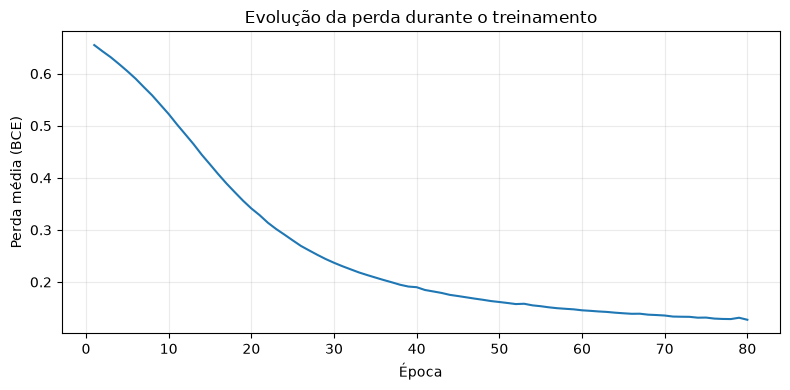

In [28]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, numero_epocas + 1), historico_perdas)
plt.xlabel("Época")
plt.ylabel("Perda média (BCE)")
plt.title("Evolução da perda durante o treinamento")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

A curva costuma diminuir quando o treinamento está encontrando parâmetros mais adequados aos dados. Isso é um sinal útil, mas não prova, sozinho, que o modelo generalizará bem. Para investigar generalização, precisamos avaliar dados que não foram usados para ajustar os parâmetros.

Acurácia no conjunto de teste: 0.950


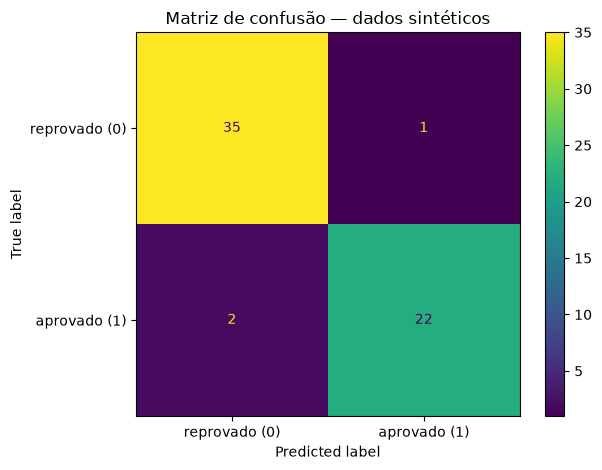

In [29]:
modelo_alunos.eval()
with torch.no_grad():
    X_test_tensor = torch.tensor(X_test, dtype=torch.float32, device=DEVICE)
    logits_teste = modelo_alunos(X_test_tensor)
    probabilidades_teste = torch.sigmoid(logits_teste).cpu().numpy().ravel()

previsoes_teste = (probabilidades_teste >= 0.5).astype(np.int64)
acuracia_teste = accuracy_score(y_test.astype(np.int64), previsoes_teste)
matriz = confusion_matrix(y_test.astype(np.int64), previsoes_teste)

print(f"Acurácia no conjunto de teste: {acuracia_teste:.3f}")
ConfusionMatrixDisplay(matriz, display_labels=["reprovado (0)", "aprovado (1)"]).plot()
plt.title("Matriz de confusão — dados sintéticos")
plt.tight_layout()
plt.show()

### Como interpretar o resultado?

- **Acurácia** é a proporção total de exemplos classificados corretamente. Ela é fácil de interpretar, mas pode esconder problemas quando as classes estão desbalanceadas.
- **Matriz de confusão** separa acertos e erros por classe. Ela ajuda a ver se o modelo erra mais em um tipo de exemplo do que em outro.
- **Perda de treinamento** descreve o ajuste nos exemplos usados para atualizar os parâmetros; não substitui a avaliação em dados não vistos.

O resultado varia um pouco conforme a inicialização e a execução. Não interprete a acurácia deste conjunto sintético como evidência sobre um problema real.

## 7. O que significa *deep learning*?

**Aprendizado profundo** (*deep learning*) é o uso de redes neurais com várias camadas de processamento. A palavra “profundo” descreve a profundidade da arquitetura; não garante que o modelo seja melhor, mais preciso ou mais inteligente.

Cada camada transforma a representação recebida e fornece uma nova representação para a seguinte. Em tarefas de visão, camadas podem aprender padrões visuais progressivamente mais abstratos; em processamento de linguagem, camadas podem combinar informações sobre tokens e contexto. Esses exemplos descrevem uma intuição geral — o que cada camada aprende depende da arquitetura, dos dados e do treinamento.

Redes mais profundas podem representar funções complexas, mas também podem exigir mais dados, memória, tempo e cuidado no treinamento. Mais camadas não significam automaticamente um modelo superior.

In [30]:
rede_rasa = nn.Sequential(
    nn.Linear(2, 8),
    nn.ReLU(),
    nn.Linear(8, 1),
)

rede_profunda = nn.Sequential(
    nn.Linear(2, 8), nn.ReLU(),
    nn.Linear(8, 8), nn.ReLU(),
    nn.Linear(8, 8), nn.ReLU(),
    nn.Linear(8, 1),
)

def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)

print("Parâmetros treináveis na rede rasa:", contar_parametros(rede_rasa))
print("Parâmetros treináveis na rede profunda:", contar_parametros(rede_profunda))

Parâmetros treináveis na rede rasa: 33
Parâmetros treináveis na rede profunda: 177


Este código compara a quantidade de parâmetros das duas arquiteturas, mas **não compara a qualidade das previsões**: ambas ainda estão com parâmetros inicializados, sem treinamento. Para afirmar que uma arquitetura funciona melhor, precisaríamos treiná-las de maneira justa e comparar seus resultados em dados de avaliação.

---
# Parte 3 — Como representar texto com números

## 8. Linguagem natural e tokenização

Computadores executam operações numéricas; textos, no entanto, chegam como sequências de símbolos. No **Processamento de Linguagem Natural (PLN)**, precisamos transformar essas sequências em representações que os algoritmos consigam processar.

A linguagem também depende muito do contexto. Compare:

- “O banco aprovou o empréstimo.”
- “Sentei no banco da praça.”

A palavra “banco” aparece nas duas frases, mas seu sentido é diferente. Essa é uma das razões pelas quais representar linguagem é mais complexo do que simplesmente converter cada palavra em um número.

**Tokenização** é a divisão de um texto em unidades chamadas *tokens*. Um token pode ser uma palavra, parte de uma palavra, pontuação ou um símbolo especial. A unidade exata depende do tokenizador; por isso, token e palavra não são sinônimos perfeitos.

Depois da tokenização, cada token recebe um índice inteiro em um vocabulário. Por exemplo, em um vocabulário didático:

$$
[\text{“o”},\text{“gato”},\text{“dormiu”}] \rightarrow [0,1,2]
$$

Esses índices são **identificadores arbitrários**. O índice 2 não significa que “dormiu” seja maior, mais importante ou mais parecido com outro token de índice 3. O índice apenas aponta para uma entrada do vocabulário.

## 9. Representação *one-hot*

A representação *one-hot* transforma cada índice num vetor com uma posição igual a 1 e as demais iguais a 0. Para um vocabulário de três tokens:

$$
\begin{aligned}
\text{gato }(0)&\rightarrow[1,0,0]\\
\text{cachorro }(1)&\rightarrow[0,1,0]\\
\text{carro }(2)&\rightarrow[0,0,1]
\end{aligned}
$$

Isso identifica cada token sem ambiguidade, mas não expressa similaridade por si só. Os vetores de “gato” e “cachorro” são ortogonais nesse espaço, embora as palavras sejam relacionadas no mundo real. Além disso, com vocabulários enormes, os vetores one-hot ficam muito grandes e quase todos os valores são zero.

In [31]:
vocabulario = {"gato": 0, "cachorro": 1, "carro": 2}
tokens_exemplo = ["gato", "cachorro", "carro"]
indices = torch.tensor([vocabulario[token] for token in tokens_exemplo])
vetores_one_hot = torch.nn.functional.one_hot(
    indices, num_classes=len(vocabulario)
).float()

print("Tokens:", tokens_exemplo)
print("Índices:", indices.tolist())
print("Matriz one-hot:\n", vetores_one_hot)
print("Formato:", tuple(vetores_one_hot.shape))

Tokens: ['gato', 'cachorro', 'carro']
Índices: [0, 1, 2]
Matriz one-hot:
 tensor([[1., 0., 0.],
        [0., 1., 0.],
        [0., 0., 1.]])
Formato: (3, 3)


## 10. Embeddings: vetores aprendidos

Um **embedding** é um vetor denso usado para representar um item, como um token. Em uma rede neural, uma camada de embeddings normalmente armazena uma matriz treinável:

$$
E \in \mathbb{R}^{V\times d}
$$

onde $V$ é o tamanho do vocabulário e $d$ é a dimensão de cada vetor. **Cada linha da matriz é o vetor de um token**. Portanto, não é necessário imaginar uma matriz completa para cada palavra: há uma tabela em que cada token seleciona uma linha.

Em `nn.Embedding(V, d)`, o índice de um token é usado para buscar sua linha na tabela. Os valores são normalmente inicializados antes do treinamento e, sozinhos, não carregam automaticamente significado semântico. Durante o treinamento de um modelo, os gradientes podem ajustar essa matriz para que os vetores ajudem a resolver a tarefa definida.

Se o objetivo e os dados permitirem, relações úteis podem surgir no espaço dos embeddings. Porém, proximidade geométrica não é uma garantia universal de “significado”: depende do modelo, do treinamento, da distribuição dos dados e da forma de comparação.

In [32]:
vocabulario_embeddings = {"gato": 0, "cachorro": 1, "animal": 2, "corre": 3}
tokens = ["gato", "corre", "animal"]
ids = torch.tensor([vocabulario_embeddings[token] for token in tokens])

camada_embedding = nn.Embedding(
    num_embeddings=len(vocabulario_embeddings),
    embedding_dim=3,
)
vetores_embedding = camada_embedding(ids)

print("Matriz de parâmetros da camada:", tuple(camada_embedding.weight.shape))
print("Formato dos IDs:", tuple(ids.shape))
print("Formato dos vetores buscados:", tuple(vetores_embedding.shape))
print("Os pesos são treináveis:", camada_embedding.weight.requires_grad)
print("Vetores iniciais (aleatórios):\n", vetores_embedding.detach())

Matriz de parâmetros da camada: (4, 3)
Formato dos IDs: (3,)
Formato dos vetores buscados: (3, 3)
Os pesos são treináveis: True
Vetores iniciais (aleatórios):
 tensor([[ 1.6245, -0.1055,  0.1475],
        [ 1.0101,  1.3533,  1.0625],
        [-0.1010, -0.9913,  0.5609]])


A saída tem formato $(3,3)$: há três tokens na sequência e cada um é representado por três números. A tabela completa tem formato $(4,3)$, pois o vocabulário do exemplo possui quatro tokens. Os valores exibidos são apenas a inicialização aleatória do exemplo; **não interprete a proximidade entre eles como semântica aprendida**.

Em modelos Transformer, a representação inicial do token é combinada com informações sobre posição e passa por camadas de atenção e redes neurais. A representação final pode, então, depender do contexto em que o token aparece. Isso difere de embeddings estáticos, que associam um vetor fixo a cada token, independentemente da frase.

## 11. TF-IDF: uma alternativa clássica para representar textos

Antes de avançarmos para Transformers, vale conhecer uma técnica tradicional de representação textual: **TF-IDF** (*Term Frequency–Inverse Document Frequency*). Ela é útil em busca textual e em modelos clássicos de classificação, incluindo o exemplo com avaliações de filmes mais adiante.

A frequência do termo (TF) mede o quanto um termo aparece em um documento. Uma definição didática simples é a proporção de ocorrências do termo entre todos os termos do documento, embora implementações possam definir e normalizar TF de maneiras diferentes. A frequência inversa de documentos (IDF) reduz o peso de termos que aparecem em muitos documentos. Uma forma suavizada de IDF usada pelo scikit-learn é:

$$
\operatorname{IDF}(t)=\log\left(\frac{1+N}{1+\operatorname{df}(t)}\right)+1
$$

Aqui, $N$ é o número de documentos e $\operatorname{df}(t)$ é o número de documentos que contêm o termo $t$. O peso TF-IDF combina TF e IDF. A ideia intuitiva é dar mais destaque a termos que são relevantes para certos documentos, mas não aparecem indiscriminadamente em todos eles.

TF-IDF não é a mesma coisa que embedding semântico. Ele produz características baseadas na distribuição dos termos no conjunto de documentos; embeddings são vetores aprendidos por uma rede ou por outro procedimento de representação.

In [33]:
documentos = [
    "o filme foi excelente e emocionante",
    "o filme foi péssimo e lento",
    "uma história emocionante e bonita",
    "um filme lento, mas interessante",
]

vetorizador_demo = TfidfVectorizer()
matriz_tfidf = vetorizador_demo.fit_transform(documentos)

print("Formato da matriz TF-IDF:", matriz_tfidf.shape)
print("Vocabulário:", vetorizador_demo.get_feature_names_out().tolist())
print("Matriz densa (apenas porque este exemplo é minúsculo):")
print(np.round(matriz_tfidf.toarray(), 2))

Formato da matriz TF-IDF: (4, 12)
Vocabulário: ['bonita', 'emocionante', 'excelente', 'filme', 'foi', 'história', 'interessante', 'lento', 'mas', 'péssimo', 'um', 'uma']
Matriz densa (apenas porque este exemplo é minúsculo):
[[0.   0.48 0.61 0.39 0.48 0.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.39 0.48 0.   0.   0.48 0.   0.61 0.   0.  ]
 [0.53 0.41 0.   0.   0.   0.53 0.   0.   0.   0.   0.   0.53]
 [0.   0.   0.   0.32 0.   0.   0.5  0.39 0.5  0.   0.5  0.  ]]


Na matriz acima, cada linha corresponde a um documento e cada coluna a um termo do vocabulário. Um valor alto indica que o termo tem peso relevante naquele documento segundo a medida TF-IDF. A matriz real costuma ser esparsa; converter para uma matriz densa pode consumir muita memória em coleções grandes.

**Cuidado com vazamento de dados:** num experimento de aprendizado de máquina, ajuste o vetorizador apenas com os textos de treino (`fit_transform`) e use o mesmo vetorizador para transformar validação ou teste (`transform`). Assim, o vocabulário e os pesos do TF-IDF não usam informação do conjunto de teste.

---
# Parte 4 — Transformers, atenção e modelos de linguagem

## 12. Por que o contexto importa?

Volte aos dois exemplos:

- “O **banco** aprovou o empréstimo.”
- “Sentei no **banco** da praça.”

Em uma representação estática, a ocorrência do token “banco” recebe o mesmo vetor inicial em ambas as frases. Para interpretar adequadamente o contexto, o modelo precisa combinar informação dos outros tokens. A arquitetura **Transformer**, apresentada no artigo *Attention Is All You Need* (Vaswani e colaboradores, 2017), popularizou o uso da atenção como mecanismo central para construir representações contextuais.

A **self-attention** permite que cada token considere outros tokens da sequência para construir uma representação atualizada. “Self” indica que as relações são calculadas dentro da própria sequência. Não significa que o modelo tenha consciência ou esteja “prestando atenção” como uma pessoa; é o nome de uma operação matemática.

## 13. A intuição de Query, Key e Value

Uma maneira útil de entender a atenção é pensar em três projeções aprendidas para cada token:

- **Query (consulta):** que informação este token procura no contexto?
- **Key (chave):** que características permitem relacionar este token às consultas dos outros?
- **Value (valor):** que informação será combinada caso este token receba atenção?

O mecanismo compara consultas e chaves, transforma os escores em pesos por meio de *softmax* e usa esses pesos para combinar os valores:

$$
\operatorname{Attention}(Q,K,V)=
\operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V
$$

$Q$, $K$ e $V$ são matrizes de consulta, chave e valor. O divisor $\sqrt{d_k}$ controla a escala dos escores, e o *softmax* transforma cada linha de escores em pesos que somam 1.

**Interpretação:** cada linha da matriz de atenção corresponde ao token que está consultando o contexto; cada coluna corresponde a um token que pode fornecer informação. Pesos maiores indicam maior contribuição relativa nessa combinação específica — não uma medida universal de importância ou verdade.

In [34]:
# Exemplo didático de self-attention em três tokens
# Para simplificar, usamos a mesma matriz como Q, K e V.
# Um Transformer real aprende projeções separadas e tem outros componentes.
sequencia = torch.tensor([
    [1.0, 0.0, 1.0, 0.0],  # token 1
    [0.0, 1.0, 1.0, 0.0],  # token 2
    [1.0, 1.0, 0.0, 1.0],  # token 3
])
rotulos_tokens = ["token 1", "token 2", "token 3"]

Q = sequencia
K = sequencia
V = sequencia
d_k = K.shape[-1]

escores = Q @ K.T / np.sqrt(d_k)
pesos_atencao = torch.softmax(escores, dim=-1)
saida_atencao = pesos_atencao @ V

print("Escores antes do softmax:\n", escores.round(decimals=3))
print("Pesos de atenção (as linhas somam 1):\n", pesos_atencao.round(decimals=3))
print("Representações combinadas:\n", saida_atencao.round(decimals=3))
print("Soma dos pesos de cada linha:", pesos_atencao.sum(dim=-1))

Escores antes do softmax:
 tensor([[1.0000, 0.5000, 0.5000],
        [0.5000, 1.0000, 0.5000],
        [0.5000, 0.5000, 1.5000]])
Pesos de atenção (as linhas somam 1):
 tensor([[0.4520, 0.2740, 0.2740],
        [0.2740, 0.4520, 0.2740],
        [0.2120, 0.2120, 0.5760]])
Representações combinadas:
 tensor([[0.7260, 0.5480, 0.7260, 0.2740],
        [0.5480, 0.7260, 0.7260, 0.2740],
        [0.7880, 0.7880, 0.4240, 0.5760]])
Soma dos pesos de cada linha: tensor([1., 1., 1.])


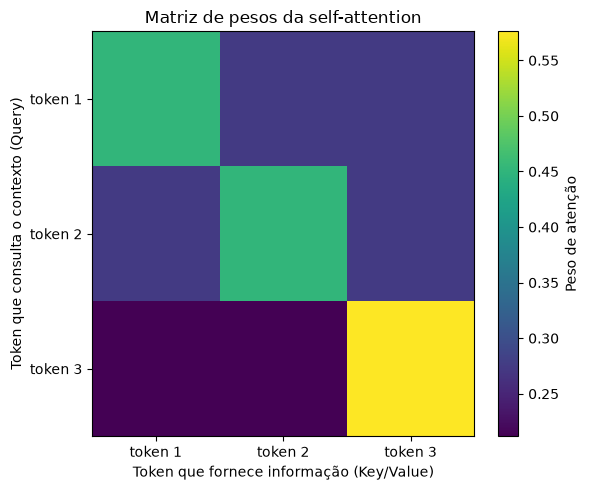

In [35]:
plt.figure(figsize=(6, 5))
plt.imshow(pesos_atencao.numpy(), aspect="auto")
plt.xticks(range(3), rotulos_tokens)
plt.yticks(range(3), rotulos_tokens)
plt.xlabel("Token que fornece informação (Key/Value)")
plt.ylabel("Token que consulta o contexto (Query)")
plt.colorbar(label="Peso de atenção")
plt.title("Matriz de pesos da self-attention")
plt.tight_layout()
plt.show()

Este exemplo é uma **visualização didática**, não uma implementação completa de um Transformer. Aqui, usamos a mesma matriz como $Q$, $K$ e $V$, sem projeções aprendidas, codificação posicional, múltiplas cabeças, conexões residuais ou treinamento. Um Transformer real inclui esses e outros componentes. O propósito desta célula é isolar a ideia central: calcular relações entre tokens e combinar informações de acordo com pesos normalizados.

### Saber que existe: além da atenção simples

Em arquiteturas modernas, a atenção costuma ser usada em **múltiplas cabeças** (*multi-head attention*) para aprender diferentes relações, e é combinada com redes neurais posição a posição, conexões residuais e normalização. O modelo também precisa representar a posição ou a ordem dos tokens. Esses detalhes são importantes, mas não são necessários para a primeira intuição sobre o mecanismo.

## 14. O que é um LLM?

**LLM** significa *Large Language Model* (grande modelo de linguagem). Muitos LLMs modernos são redes neurais profundas baseadas em Transformers, treinadas com grandes coleções de texto para aprender padrões da linguagem. Em um modelo autorregressivo, dada uma sequência de tokens, o modelo estima uma distribuição de probabilidades para o próximo token:

$$
P(x_{t+1}\mid x_1,x_2,\ldots,x_t)
$$

Durante a geração, um token é escolhido, adicionado ao contexto, e o processo se repete para gerar o token seguinte. Embora a resposta apareça para nós como um texto, o modelo a constrói sucessivamente.

O treinamento inicial costuma aprender a prever tokens em grandes volumes de dados. Depois, podem existir etapas adicionais de ajuste para seguir instruções e responder de maneira mais útil. Os detalhes variam conforme o sistema.

### Um LLM não é a mesma coisa que a aplicação de chat

É útil distinguir dois níveis:

- **Modelo de linguagem:** a rede que processa o contexto e calcula distribuições para o próximo token.
- **Aplicação conversacional:** o sistema que organiza mensagens, instruções, histórico, ferramentas, políticas e a interação com o usuário, além de chamar o modelo.

Um sistema baseado em LLM não consulta automaticamente uma fonte universal de verdade. Ele pode produzir texto fluente e, mesmo assim, apresentar fatos incorretos ou referências inventadas. Avaliar esses sistemas exige olhar para factualidade, coerência, robustez, privacidade, vieses e segurança — não apenas para a fluência da resposta.

---
# Parte 5 — Um estudo de caso completo (opcional): classificação de sentimentos no IMDB

Esta seção preserva um exemplo mais extenso para consulta. Ele conecta representação de texto e rede neural: textos de avaliações são transformados por TF-IDF, e uma rede neural classifica o sentimento como negativo (0) ou positivo (1).

**Este exemplo não é um LLM nem um Transformer.** É um classificador supervisionado simples, útil para ilustrar um fluxo completo de aprendizado de máquina em texto.

A execução requer conexão com a internet, o pacote `datasets` e memória suficiente para armazenar uma matriz densa de características. O código limita o tamanho da amostra para manter o exemplo didático. Caso o ambiente esteja limitado, esta seção pode ser lida sem ser executada.

In [36]:
# Se necessário, instale o pacote antes de continuar:

from datasets import load_dataset

imdb = load_dataset("stanfordnlp/imdb")
quantidade_treino = 1800
quantidade_teste = 600

amostra_treino = imdb["train"].shuffle(seed=SEED).select(range(quantidade_treino))
amostra_teste = imdb["test"].shuffle(seed=SEED).select(range(quantidade_teste))

print("Exemplos de treino:", len(amostra_treino))
print("Exemplos de teste:", len(amostra_teste))
print("Exemplo de rótulo:", amostra_treino[0]["label"], "(0 = negativo; 1 = positivo)")

Exemplos de treino: 1800
Exemplos de teste: 600
Exemplo de rótulo: 1 (0 = negativo; 1 = positivo)


### Vetorização com TF-IDF

O vetorizador aprende seu vocabulário **somente com os textos de treino**. Depois, transforma os textos de treino e teste na mesma representação. `max_features` limita o vocabulário às características mais relevantes segundo o critério do vetorizador. A conversão para matriz densa simplifica a integração com este exemplo de PyTorch, mas pode consumir bastante memória em tarefas maiores.

In [37]:
vetorizador_imdb = TfidfVectorizer(
    max_features=4000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
)

X_treino_np = vetorizador_imdb.fit_transform(amostra_treino["text"]).astype(np.float32).toarray()
X_teste_np = vetorizador_imdb.transform(amostra_teste["text"]).astype(np.float32).toarray()
y_treino_np = np.asarray(amostra_treino["label"], dtype=np.float32).reshape(-1, 1)
y_teste_np = np.asarray(amostra_teste["label"], dtype=np.float32).reshape(-1, 1)

print("Formato da matriz de treino:", X_treino_np.shape)
print("Formato da matriz de teste:", X_teste_np.shape)
print("Quantidade de termos no vocabulário:", len(vetorizador_imdb.vocabulary_))

Formato da matriz de treino: (1800, 4000)
Formato da matriz de teste: (600, 4000)
Quantidade de termos no vocabulário: 4000


### Definindo o modelo

A rede recebe o vetor TF-IDF do texto, transforma-o por uma camada escondida com ReLU e produz um logit. `Dropout` desativa aleatoriamente parte das ativações durante o treinamento, como uma forma simples de regularização. Ele é desligado automaticamente quando usamos `modelo.eval()` para avaliar.

In [38]:
X_treino = torch.from_numpy(X_treino_np)
y_treino = torch.from_numpy(y_treino_np)
X_teste = torch.from_numpy(X_teste_np)
y_teste = torch.from_numpy(y_teste_np)

loader_imdb = DataLoader(
    TensorDataset(X_treino, y_treino),
    batch_size=64,
    shuffle=True,
)

modelo_imdb = nn.Sequential(
    nn.Linear(X_treino.shape[1], 64),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(64, 1),
)

perda_imdb = nn.BCEWithLogitsLoss()
otimizador_imdb = torch.optim.Adam(modelo_imdb.parameters(), lr=0.001)
print(modelo_imdb)

Sequential(
  (0): Linear(in_features=4000, out_features=64, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=64, out_features=1, bias=True)
)


### Treinamento

O laço de treinamento segue o mesmo ciclo visto anteriormente. Como estamos usando uma amostra limitada, o resultado é uma demonstração do fluxo, não uma tentativa de obter o melhor classificador possível para o IMDB.

In [39]:
numero_epocas_imdb = 3
historico_imdb = []

for epoca in range(numero_epocas_imdb):
    modelo_imdb.train()
    soma_perdas = 0.0

    for lote_X, lote_y in loader_imdb:
        otimizador_imdb.zero_grad()
        logits_lote = modelo_imdb(lote_X)
        perda = perda_imdb(logits_lote, lote_y)
        perda.backward()
        otimizador_imdb.step()
        soma_perdas += perda.item() * len(lote_X)

    perda_media = soma_perdas / len(loader_imdb.dataset)
    historico_imdb.append(perda_media)
    print(f"Época {epoca + 1}: perda média = {perda_media:.4f}")

Época 1: perda média = 0.6859
Época 2: perda média = 0.6302
Época 3: perda média = 0.5414


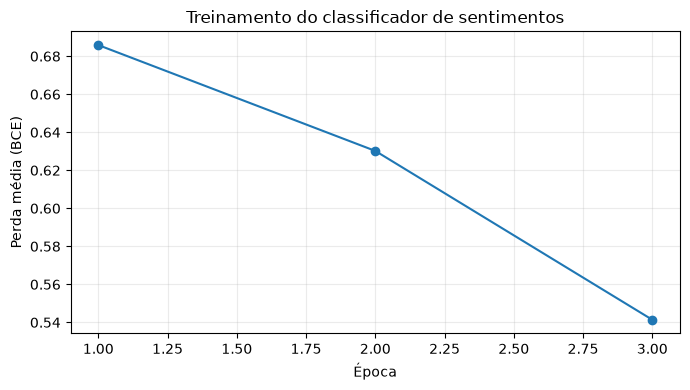

In [40]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, numero_epocas_imdb + 1), historico_imdb, marker="o")
plt.xlabel("Época")
plt.ylabel("Perda média (BCE)")
plt.title("Treinamento do classificador de sentimentos")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Avaliação no conjunto de teste

O conjunto de teste é usado aqui ao final para estimar como o classificador se comporta em textos que não entraram no treinamento. A acurácia dá uma visão geral, enquanto a matriz de confusão mostra os erros por classe.

Acurácia no teste (amostra IMDB): 0.830


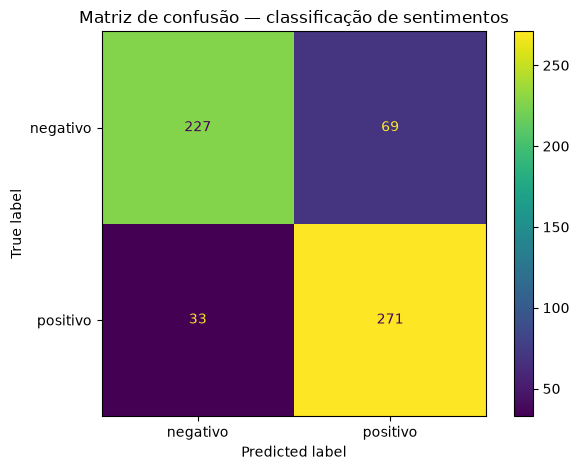

In [41]:
modelo_imdb.eval()
with torch.no_grad():
    probabilidades_imdb = torch.sigmoid(modelo_imdb(X_teste)).squeeze(1).numpy()

previsoes_imdb = (probabilidades_imdb >= 0.5).astype(np.int64)
rotulos_teste_imdb = y_teste.squeeze(1).numpy().astype(np.int64)
acuracia_imdb = accuracy_score(rotulos_teste_imdb, previsoes_imdb)
matriz_imdb = confusion_matrix(rotulos_teste_imdb, previsoes_imdb)

print(f"Acurácia no teste (amostra IMDB): {acuracia_imdb:.3f}")
ConfusionMatrixDisplay(
    matriz_imdb,
    display_labels=["negativo", "positivo"],
).plot()
plt.title("Matriz de confusão — classificação de sentimentos")
plt.tight_layout()
plt.show()

### Limitações deste modelo

- O modelo usa TF-IDF, não embeddings aprendidos por uma arquitetura Transformer.
- A amostra é pequena em relação ao conjunto original; o resultado depende da amostragem, da inicialização e do treinamento.
- Acurácia não descreve todos os aspectos de qualidade de um classificador.
- O exemplo foi simplificado para fins didáticos. Em aplicações reais, também seria necessário considerar validação, ajuste de hiperparâmetros, custo de falsos positivos e falsos negativos, reprodutibilidade e possíveis vieses nos dados.

O valor pedagógico do exemplo está no pipeline: dados textuais → vetorização → modelo → função de perda → treinamento → avaliação.

---
# Revisão final

## O encadeamento de ideias

1. Um neurônio combina entradas por meio de pesos e viés, e pode aplicar uma função de ativação.
2. Uma rede conecta várias dessas operações em camadas.
3. A função de perda mede o erro; o backpropagation calcula gradientes; o otimizador atualiza os parâmetros.
4. Uma rede com várias camadas pode aprender representações úteis, mas a profundidade por si só não garante qualidade.
5. Para processar texto, precisamos de representações numéricas. One-hot identifica tokens; TF-IDF representa documentos por pesos de termos; embeddings são vetores treináveis.
6. A self-attention combina informações entre tokens e ajuda Transformers a construir representações contextuais.
7. LLMs modernos podem gerar texto prevendo tokens sucessivos, mas suas respostas precisam ser verificadas.